# 01 — First look: the Melbourne CBD weekday

**Goal of this notebook:** establish a trustworthy panel, then find out whether
the naive answer to "how empty is the CBD on Mondays and Fridays" survives
contact with the data.

It does not. That's the interesting part.

Run `python src/fetch_data.py` first if `data/raw/` is empty.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw")
OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

counts = pd.read_parquet(RAW / "pedestrian_counts.parquet")
sensors = pd.read_parquet(RAW / "sensor_locations.parquet")

counts["sensing_date"] = pd.to_datetime(counts["sensing_date"])
counts["month"] = counts["sensing_date"].dt.to_period("M")
counts["dow"] = counts["sensing_date"].dt.dayofweek

print(f"{len(counts):,} rows")
print(f"{counts.sensing_date.min().date()} -> {counts.sensing_date.max().date()}")
print(f"{counts.location_id.nunique()} sensors in counts, {len(sensors)} in locations table")

1,612,972 rows
2024-08-03 -> 2026-08-02
103 sensors in counts, 134 in locations table


## Step 1 — Profile before you plot

Two things to notice immediately.

**The date range.** The documentation says this data goes back to 2009. It
doesn't — the published dataset is a rolling 24-month window. Check the range
above. This is why the project question is about weekday *structure* rather than
recovery against a 2019 baseline: that baseline isn't obtainable here.

**The join asymmetry.** More sensors in the locations table than in the counts,
*and* some count rows with no matching sensor name. An inner join would silently
drop rows. Look at the damage before choosing.

In [11]:
print("Nulls in counts:")
print(counts.isna().sum()[lambda s: s > 0].to_string() or "  none")

in_counts = set(counts.location_id.unique())
in_sensors = set(sensors.location_id.unique())
print(f"\nsensors with counts but no location record: {len(in_counts - in_sensors)}")
print(f"sensors with location record but no counts:  {len(in_sensors - in_counts)}")
print(f"\nan inner join would drop {(~counts.location_id.isin(in_sensors)).sum():,} count rows")

# Sanity check the arithmetic the schema implies.
bad = (counts.direction_1 + counts.direction_2 != counts.pedestriancount).sum()
print(f"rows where direction_1 + direction_2 != pedestriancount: {bad:,}")

Nulls in counts:
sensor_name    25639
location       25639

sensors with counts but no location record: 3
sensors with location record but no counts:  34

an inner join would drop 25,639 count rows
rows where direction_1 + direction_2 != pedestriancount: 0


## Step 2 — The trap: sensor churn

The sensor network is not fixed. Councils install and decommission units
constantly. If you sum counts across all sensors and plot it over time, a rising
line means *more sensors*, not more people.

This is the single most common way this dataset gets misused. Plot it both ways
and the problem is obvious.

sensor count went 94 -> 102 (+8.5%)


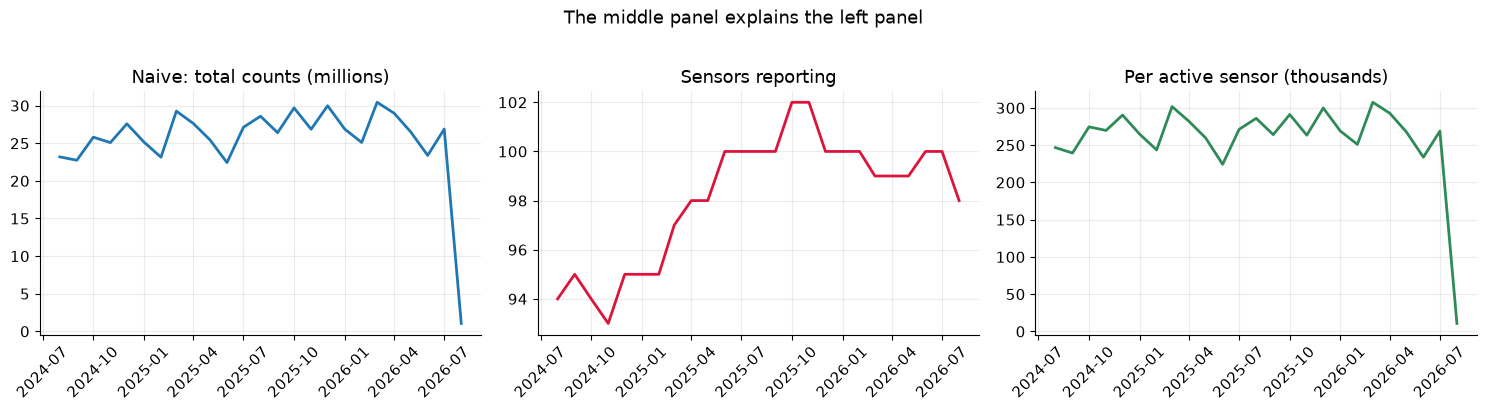

In [4]:
monthly = counts.groupby("month").agg(
    total=("pedestriancount", "sum"),
    n_sensors=("location_id", "nunique"),
)
monthly["per_sensor"] = monthly.total / monthly.n_sensors

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
x = monthly.index.to_timestamp()

axes[0].plot(x, monthly.total / 1e6, lw=2)
axes[0].set_title("Naive: total counts (millions)")

axes[1].plot(x, monthly.n_sensors, lw=2, color="crimson")
axes[1].set_title("Sensors reporting")

axes[2].plot(x, monthly.per_sensor / 1e3, lw=2, color="seagreen")
axes[2].set_title("Per active sensor (thousands)")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("The middle panel explains the left panel", y=1.02)
fig.tight_layout()

print(f"sensor count went {monthly.n_sensors.iloc[0]} -> {monthly.n_sensors.max()} "
      f"({monthly.n_sensors.max() / monthly.n_sensors.iloc[0] - 1:+.1%})")

## Step 3 — Build a balanced panel

The fix: keep only sensors that reported in **every** month. Now any change over
time is a change in behaviour, not in instrumentation.

You lose some sensors. That's the correct trade — a smaller honest panel beats a
larger one that answers a different question each month.

Also note what "missing" means here. An offline sensor produces **no row**, not
a zero row. If you reindex onto a complete hourly grid and `fillna(0)`, you will
invent a decline out of maintenance downtime.

In [5]:
n_months = counts.month.nunique()
months_per_sensor = counts.groupby("location_id").month.nunique()
balanced_ids = months_per_sensor[months_per_sensor == n_months].index

panel = counts[counts.location_id.isin(balanced_ids)].copy()

n_days = panel.sensing_date.nunique()
expected = len(balanced_ids) * n_days * 24
print(f"balanced panel: {len(balanced_ids)} of {counts.location_id.nunique()} sensors")
print(f"rows: {len(panel):,} of {expected:,} possible = {len(panel)/expected:.1%} complete")
print(f"\nthe missing {1 - len(panel)/expected:.1%} is genuine downtime — leave it missing")

balanced panel: 87 of 103 sensors
rows: 1,441,236 of 1,524,240 possible = 94.6% complete

the missing 5.4% is genuine downtime — leave it missing


## Step 4 — The naive answer

Average daily total by weekday. This is what almost every public analysis of
this dataset does, and what most news coverage of "CBD recovery" is built on.

The hybrid-work hypothesis predicts Monday and Friday both sit well below
Tuesday–Thursday. Let's see.

  Mon  -12.4%
  Tue   -3.0%
  Wed   -0.9%
  Thu   +3.9%
  Fri   +6.9%
  Sat   +7.7%
  Sun  -11.8%


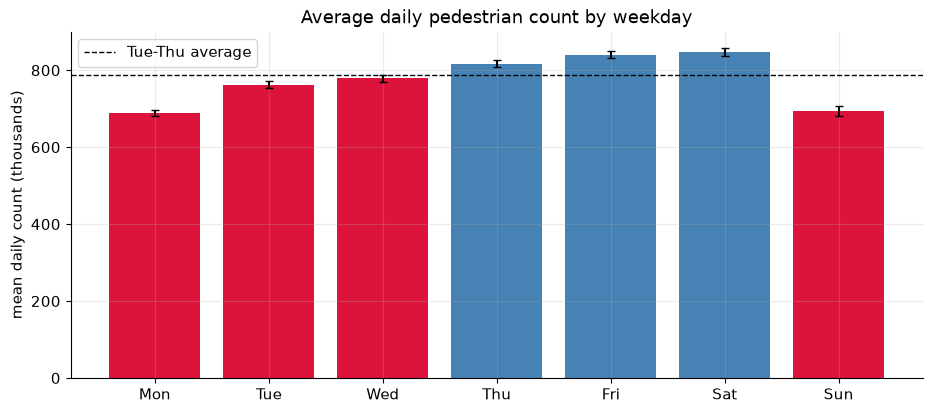

In [6]:
daily = panel.groupby("sensing_date", as_index=False).pedestriancount.sum()
daily["dow"] = daily.sensing_date.dt.dayofweek

by_dow = daily.groupby("dow").pedestriancount.agg(["mean", "sem"])
midweek = by_dow.loc[[1, 2, 3], "mean"].mean()
by_dow["vs_midweek"] = by_dow["mean"] / midweek - 1

fig, ax = plt.subplots()
colors = ["crimson" if v < 0 else "steelblue" for v in by_dow.vs_midweek]
ax.bar(DAYS, by_dow["mean"] / 1e3, yerr=by_dow["sem"] / 1e3, color=colors, capsize=3)
ax.axhline(midweek / 1e3, ls="--", c="k", lw=1, label="Tue-Thu average")
ax.set_ylabel("mean daily count (thousands)")
ax.set_title("Average daily pedestrian count by weekday")
ax.legend()

for d, v in zip(DAYS, by_dow.vs_midweek):
    print(f"  {d}  {v:+6.1%}")

### That is not what the hypothesis predicted

Monday is down 12%, as expected. But **Friday is one of the busiest days of the
week**, and Saturday is busier still.

The tempting conclusion is that Melbourne's CBD is fine and the hybrid-work
story is overblown. Before accepting that, ask a question that any daily total
cannot answer: *busy with whom, and when?*

A day is not one thing. Sum it and you throw away the only dimension that
distinguishes a commuter from a diner.

## Step 5 — Split the day

Same panel, same sensors, same period. The only change is that we stop summing
across hours.

    Morning commute (7-9am) Evening commute (5-6pm) Midday (11am-2pm) Night (8-11pm)
Mon                  -16.9%                  -15.2%             -6.7%         -23.5%
Tue                   +0.7%                   -3.4%             -1.3%         -10.1%
Wed                   -1.7%                   -0.5%             -1.5%          -1.1%
Thu                   +1.0%                   +4.0%             +2.8%         +11.2%
Fri                  -19.7%                   +1.6%             +0.5%         +56.9%
Sat                  -53.7%                   -4.5%             +6.0%         +65.9%
Sun                  -57.1%                  -27.3%             +1.5%         -10.8%


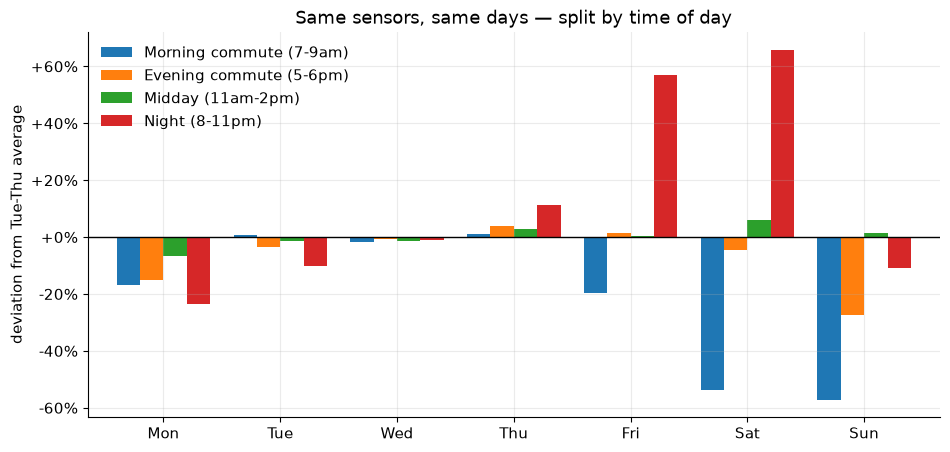

In [7]:
WINDOWS = {
    "Morning commute (7-9am)": (7, 9),
    "Evening commute (5-6pm)": (17, 18),
    "Midday (11am-2pm)":       (11, 14),
    "Night (8-11pm)":          (20, 23),
}

rows = []
for label, (lo, hi) in WINDOWS.items():
    sub = panel[panel.hourday.between(lo, hi)]
    d = sub.groupby("sensing_date", as_index=False).pedestriancount.sum()
    d["dow"] = d.sensing_date.dt.dayofweek
    g = d.groupby("dow").pedestriancount.mean()
    rows.append((g / g.loc[[1, 2, 3]].mean() - 1).rename(label))

profile = pd.concat(rows, axis=1)
profile.index = DAYS

fig, ax = plt.subplots(figsize=(11, 5))
profile.plot(kind="bar", ax=ax, width=0.8)
ax.axhline(0, c="k", lw=1)
ax.set_ylabel("deviation from Tue-Thu average")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_title("Same sensors, same days — split by time of day")
ax.legend(frameon=False)
plt.xticks(rotation=0)

print(profile.map(lambda v: f"{v:+.1%}").to_string())

### There it is

**Friday morning is the emptiest weekday morning of the week — emptier than
Monday.** Friday night is the busiest weeknight by a wide margin, +57% over
midweek.

The two cancel almost exactly in the daily total. The aggregation that every
public analysis uses destroys precisely the effect that everyone is arguing
about.

So the CBD hasn't lost people. It has traded commuters for visitors. That is a
substantially different claim from either "the city is hollowed out" or "the
city has recovered," and it has different policy implications: the businesses
hurt are the ones selling coffee at 8am, not the ones selling dinner at 8pm.

**Careful — this is not yet a finding.** It is an uncontrolled description.
Before it becomes a result you need public holidays (Melbourne Cup is a Tuesday;
AFL Grand Final Friday is a Friday), weather, and school terms. That's notebook
02. Resist the urge to write the conclusion now.

## Step 6 — Is it moving?

Split the window in half and re-run. If return-to-office mandates are working,
the morning deficit should be shrinking.

In [8]:
midpoint = panel.sensing_date.min() + (panel.sensing_date.max() - panel.sensing_date.min()) / 2
panel["half"] = np.where(panel.sensing_date < midpoint, "Year 1", "Year 2")

am = panel[panel.hourday.between(7, 9)]
d = am.groupby(["half", "sensing_date"], as_index=False).pedestriancount.sum()
d["dow"] = d.sensing_date.dt.dayofweek

for half, sub in d.groupby("half"):
    g = sub.groupby("dow").pedestriancount.mean()
    mid = g.loc[[1, 2, 3]].mean()
    print(f"{half}  morning commute:  Mon {g.loc[0]/mid-1:+.1%}   Fri {g.loc[4]/mid-1:+.1%}"
          f"   | Tue-Thu level {mid/1e3:.0f}k")

Year 1  morning commute:  Mon -17.6%   Fri -20.2%   | Tue-Thu level 108k
Year 2  morning commute:  Mon -16.2%   Fri -19.2%   | Tue-Thu level 109k


## Save the panel and stop

Write the cleaned panel to `data/processed/` so notebook 02 starts from a known
state rather than re-deriving it.

**Next, in order:**

1. Add Victorian public holidays and re-run step 5. Expect the Friday morning
   deficit to shrink somewhat — Grand Final Friday and Good Friday are in there.
2. Add BOM daily rainfall for station 086338.
3. Fit `log(count) ~ C(dow) + C(month) + C(location_id) + holiday + rain`.
   The `location_id` fixed effect is what makes sensor churn stop mattering, and
   working out *why* that's true is worth an hour of your time.
4. Hand-label the balanced-panel sensors into precincts, then cluster them by
   their 24-hour weekday shape and see where your labels and the clustering
   disagree.

In [9]:
PROC = Path("../data/processed")
PROC.mkdir(exist_ok=True)

panel.drop(columns=["half"]).to_parquet(PROC / "balanced_panel.parquet", index=False)
sensors[sensors.location_id.isin(balanced_ids)].to_parquet(
    PROC / "balanced_sensors.parquet", index=False
)

print(f"saved {len(panel):,} rows, {len(balanced_ids)} sensors -> data/processed/")

saved 1,441,236 rows, 87 sensors -> data/processed/


In [12]:
flinders = counts[(counts.sensor_name.str.contains('Fli', na=False)) &
                  (counts.hourday.between(7, 9))].copy()
flinders['dow'] = flinders.sensing_date.dt.day_name()
print(flinders.groupby('dow').pedestriancount.mean().round(0))

dow
Friday       357.0
Monday       408.0
Saturday     172.0
Sunday       150.0
Thursday     520.0
Tuesday      521.0
Wednesday    502.0
Name: pedestriancount, dtype: float64


In [13]:
print(counts[counts.sensor_name.str.contains('Fli', na=False)].sensor_name.unique())

<ArrowStringArray>
['FliSS_T', 'FliS_T', 'Fli114F_T', 'Fli114C_T', 'SprFli_T']
Length: 5, dtype: str


In [14]:
fli = counts[counts.sensor_name.str.contains('Fli', na=False) &
             counts.hourday.between(7, 9)].copy()
fli['dow'] = fli.sensing_date.dt.dayofweek

t = fli.pivot_table(index='sensor_name', columns='dow',
                    values='pedestriancount', aggfunc='mean')
mid = t[[1, 2, 3]].mean(axis=1)
out = pd.DataFrame({
    'TueThu': mid.round(0),
    'Mon_%': ((t[0] / mid - 1) * 100).round(1),
    'Fri_%': ((t[4] / mid - 1) * 100).round(1),
}).sort_values('Fri_%')
print(out)

             TueThu  Mon_%  Fri_%
sensor_name                      
FliS_T       1004.0  -21.0  -35.3
Fli114F_T     329.0  -23.4  -28.8
SprFli_T      103.0  -20.1  -25.3
Fli114C_T      33.0  -20.8  -21.7
FliSS_T       606.0  -18.6  -17.6
